# STN summary: permutation space vs. encoder embeddings
Search trajectory networks (STN) of GA runs on the TSP with clustered locations: k centers are drawn from the elites and every elite belongs to its nearest center, in the permutation space by edge distance and in a representation by L2 distance. The question is how well the STN of a representation reproduces the STN of the permutation space.

**Setup** (`src/dl_permutations/stn_config.yaml`). Instance 1 (`tsp_config.seed` 21). Encoders are trained on the elites of the training runs (runs 0-99 without the validation runs) and evaluated on 100 held-out test runs (seeds 1100-1199):
- encoders: the LSTM of the pipeline, an MLP on the edge incidence vector and DeepSets over the edges, trained on triplets ordered by edge distance for 200 epochs, 3 seeds each, next to their untrained initializations;
- compressions without learning, fitted on the same training elites: classical MDS of the edge distances to 64 dimensions (the reference) and PCA of the edge incidence vectors to 64 and 2 dimensions. The squared L2 distance of two incidence vectors is twice their edge distance.

**Metrics** (ARI, soft, funnel and end_equal averaged over k = 20 and 50):
- ARI: adjusted Rand index of the locations in both spaces;
- soft: per-tour Spearman correlation of the distances to the k centers in both spaces;
- spearman: Spearman correlation of all pair distances;
- recall@5: share of the 5 nearest distinct tours that lie within the 5th smallest edge distance;
- funnel: -|best-strength of the representation's STN - best-strength of the permutation-space STN|;
- end_equal: share of runs whose last elite lands in the same location in both spaces;
- gen_r2: out-of-fold R^2 of a ridge regression of the generation (folds grouped by run).

In [1]:
import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir("..")

## Instance 1, test runs
Mean ± sd over the 3 seeds for the encoders; one value for the compressions without learning.

In [2]:
import csv

import matplotlib.pyplot as plt
import numpy as np
import torch
from dl_permutations import stn_encoders as E
from dl_permutations import stn_summary as P
from dl_permutations.stn_clusters import edge_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test, fit = E.test_runs("tsp21"), E.training_elites("tsp21")
coords = {name: [Z] for name, Z in P.baseline_coordinates(test["perm"], fit["perm"]).items()}
for arch in E.ARCHITECTURES:
    coords[arch] = [E.embed_tours(E.load_or_train(arch, device, seed=s), test["perm"], device) for s in E.SEEDS]
for arch in E.ARCHITECTURES:
    coords[f"{arch} untrained"] = [E.embed_tours(E.random_init(arch, device, s), test["perm"], device)
                                   for s in E.SEEDS]
rows = P.summary_rows({name: [P.metrics(test, Z) for Z in Zs] for name, Zs in coords.items()})
print(f"{len(np.unique(test['run_id']))} test runs, {len(test['perm'])} elites; "
      f"{len(fit['perm'])} training elites for the compressions\n")
print(P.format_rows(rows))
with open(os.path.join(E.OUTPUT_DIR, "stn_summary_table.csv"), "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["variant", "n", *P.METRICS, *[f"{m} sd" for m in P.METRICS]])
    writer.writeheader()
    writer.writerows(rows)

100 test runs, 1850 elites; 1518 training elites for the compressions

                variant            ARI           soft       spearman       recall@5          funnel      end_equal         gen_r2
      classical MDS(64)          0.489          0.912          0.919          0.875          -0.035          0.795          0.554
   PCA(64) of incidence          0.287          0.771          0.717          0.779          -0.160          0.705          0.607
    PCA(2) of incidence          0.020          0.244          0.179          0.025          -0.450          0.255          0.514
                   lstm  0.093 ± 0.002  0.685 ± 0.004  0.804 ± 0.000  0.293 ± 0.003  -0.142 ± 0.055  0.397 ± 0.020  0.496 ± 0.012
          incidence_mlp  0.121 ± 0.008  0.740 ± 0.000  0.845 ± 0.000  0.371 ± 0.002  -0.132 ± 0.039  0.447 ± 0.038  0.516 ± 0.013
          edge_deepsets  0.126 ± 0.007  0.741 ± 0.011  0.844 ± 0.006  0.353 ± 0.018  -0.132 ± 0.025  0.430 ± 0.026  0.518 ± 0.004
         lstm untra

## Replication over five instances
TSP seeds 101-105: per instance, the reference and PCA(64) fitted on its training elites and `incidence_mlp` trained on it (seed 0), on its 100 test runs; then mean ± sd over the instances.

In [3]:
rep = P.replication(device)
print(P.format_rows([{"variant": f"{instance}: {name}", **m} for instance, res in rep.items()
                     for name, m in res.items()]), end="\n\n")
names = list(next(iter(rep.values())))
print(P.format_rows(P.summary_rows({name: [res[name] for res in rep.values()] for name in names})))

                     variant    ARI   soft  spearman  recall@5  funnel  end_equal  gen_r2
   tsp101: classical MDS(64)  0.382  0.908     0.910     0.825  -0.075      0.645   0.541
tsp101: PCA(64) of incidence  0.262  0.811     0.701     0.750  -0.275      0.645   0.597
       tsp101: incidence_mlp  0.112  0.747     0.854     0.343  -0.060      0.455   0.543
   tsp102: classical MDS(64)  0.401  0.917     0.918     0.864  -0.140      0.745   0.593
tsp102: PCA(64) of incidence  0.246  0.746     0.705     0.772  -0.110      0.640   0.637
       tsp102: incidence_mlp  0.122  0.742     0.837     0.353  -0.190      0.535   0.547
   tsp103: classical MDS(64)  0.447  0.919     0.924     0.871  -0.135      0.760   0.575
tsp103: PCA(64) of incidence  0.272  0.764     0.725     0.782  -0.100      0.690   0.620
       tsp103: incidence_mlp  0.124  0.744     0.840     0.375  -0.125      0.435   0.555
   tsp104: classical MDS(64)  0.422  0.930     0.920     0.855  -0.045      0.745   0.565
tsp104: PC

## Figures
STN of the permutation space, of the reference and of `incidence_mlp` (seed 0) for k = 10 and 20 on the test runs of instance 1, with the same centers, node positions (metric MDS of the centers' edge distances) and scales. Then the first 5 test runs (by run id) in the first two principal components of the incidence vectors and of the `incidence_mlp` embedding, both fitted on the training elites. Saved to `outputs/stn_summary_k10.png`, `outputs/stn_summary_k20.png` and `outputs/stn_summary_trajectories.png`.

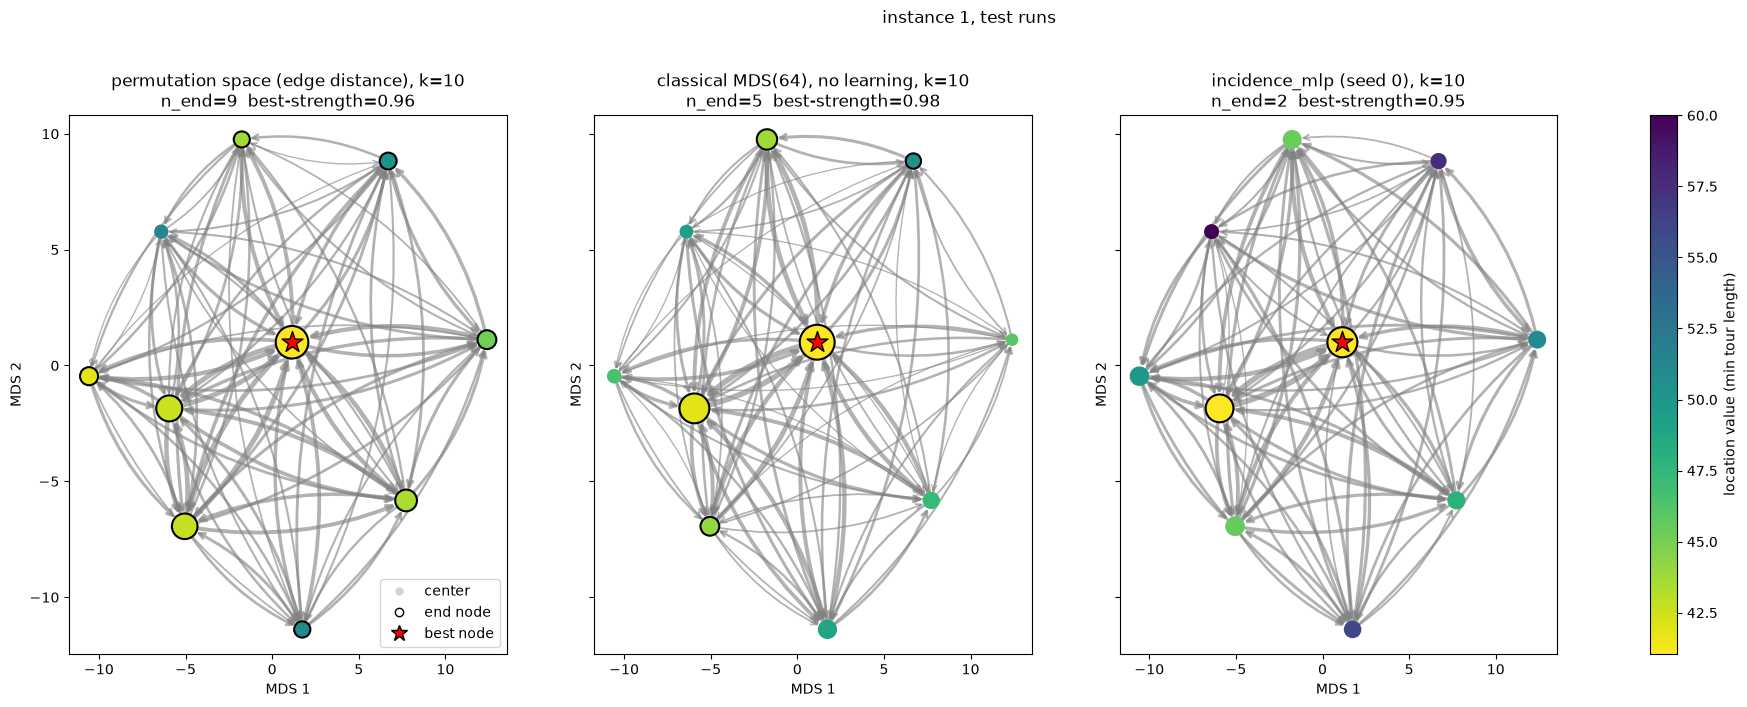

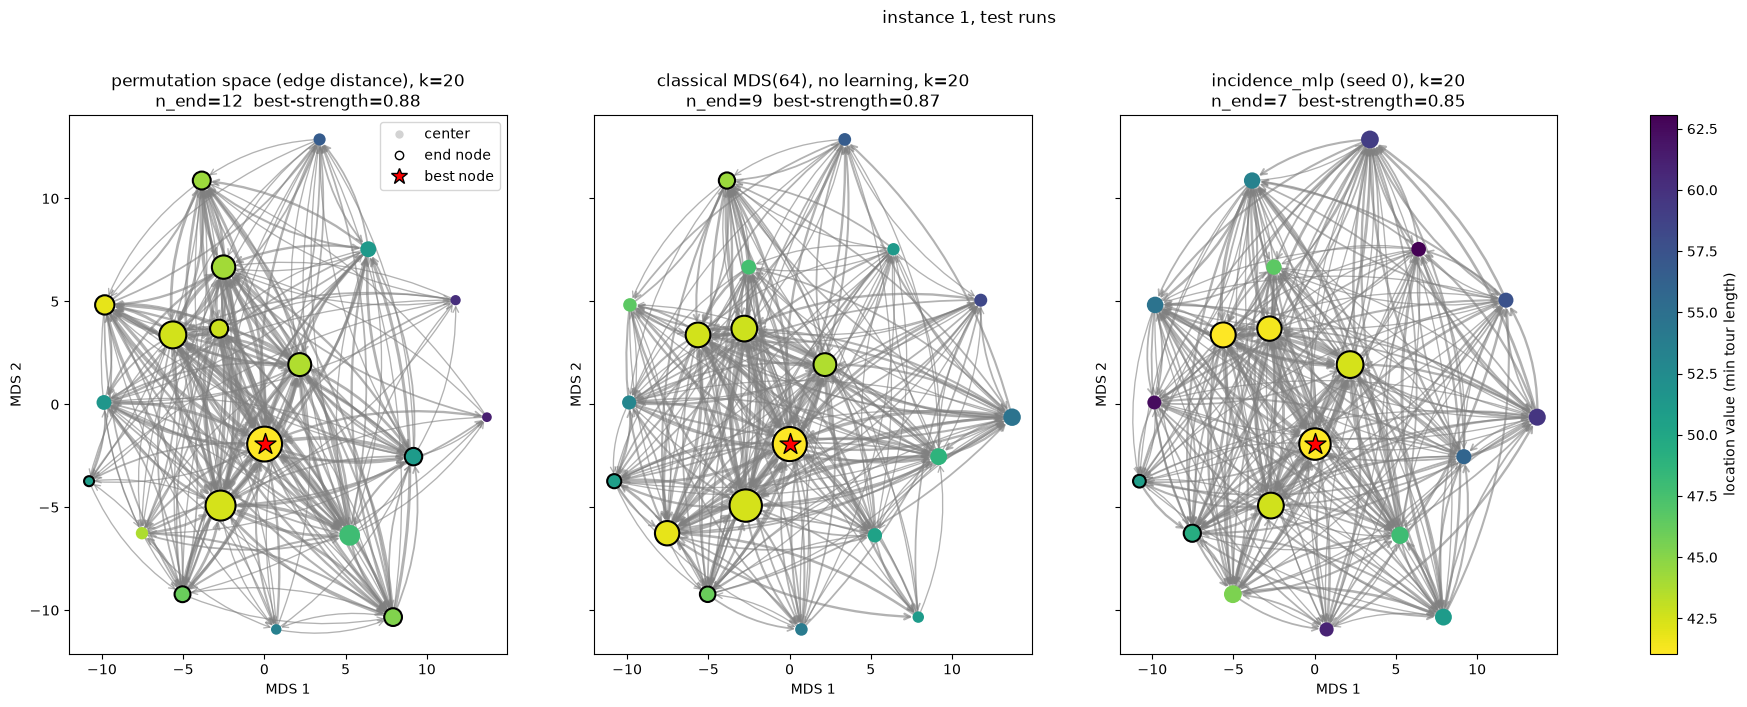

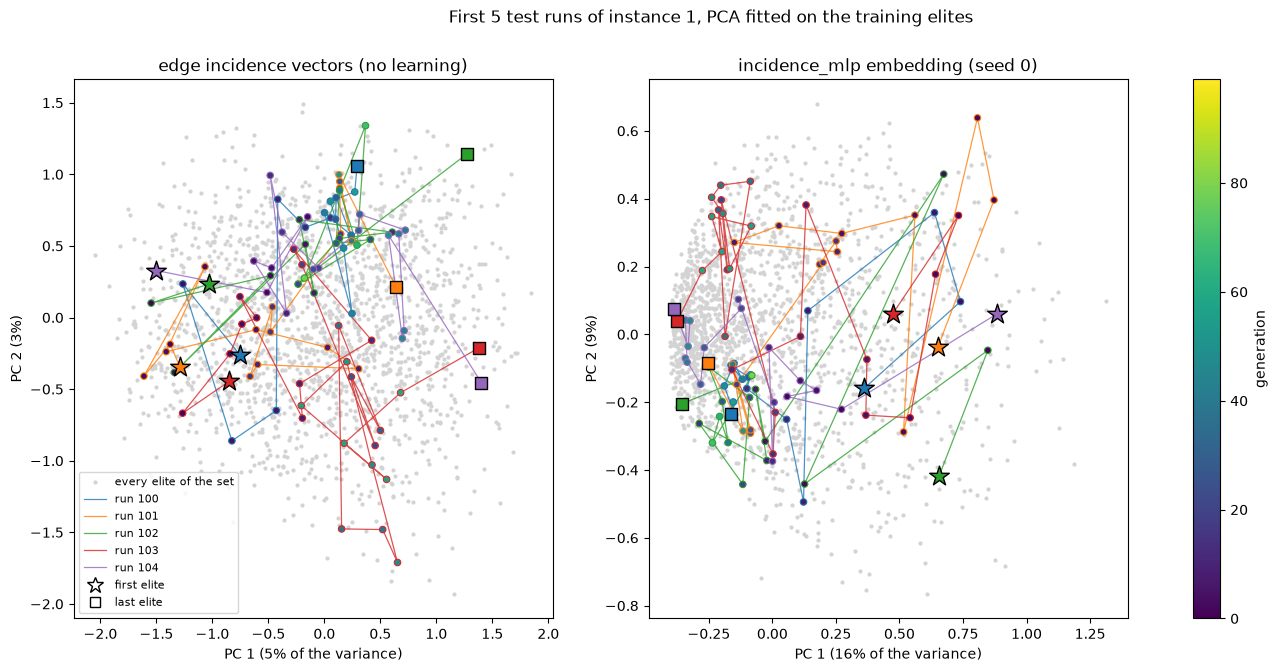

In [4]:
for k in P.FIGURE_KS:
    fig = P.stn_figure(test, {f"{P.REFERENCE}, no learning": coords[P.REFERENCE][0],
                              "incidence_mlp (seed 0)": coords["incidence_mlp"][0]}, k, "instance 1, test runs")
    fig.savefig(os.path.join(E.OUTPUT_DIR, f"stn_summary_k{k}.png"), dpi=150, bbox_inches="tight")
    plt.show()
mlp = E.load_or_train("incidence_mlp", device)
fig = P.trajectories_figure(
    test,
    {"edge incidence vectors (no learning)": edge_matrix(fit["perm"]),
     "incidence_mlp embedding (seed 0)": E.embed_tours(mlp, fit["perm"], device)},
    {"edge incidence vectors (no learning)": edge_matrix(test["perm"]),
     "incidence_mlp embedding (seed 0)": coords["incidence_mlp"][0]},
    np.unique(test["run_id"])[:5], "First 5 test runs of instance 1, PCA fitted on the training elites")
fig.savefig(os.path.join(E.OUTPUT_DIR, "stn_summary_trajectories.png"), dpi=150, bbox_inches="tight")
plt.show()

## Conclusions
- Classical MDS(64) of the edge distances, without any learning, agrees with the permutation space better than every trained encoder: on instance 1 in every metric (ARI 0.489 vs 0.121 for `incidence_mlp`, soft 0.912 vs 0.740, Spearman 0.919 vs 0.845, recall@5 0.875 vs 0.371, end_equal 0.795 vs 0.447, funnel -0.035 vs -0.132), and on each of the five replication instances in ARI, soft, Spearman, recall@5 and end_equal; the funnel and the generation probe are close there (means -0.106 vs -0.109 and 0.562 vs 0.543).
- These metrics are defined by the edge distance, which classical MDS approximates directly, so they favor it by construction; the encoders learn the edge distance only through triplets.
- Training improves every architecture over its untrained initialization in ARI, soft, Spearman and end_equal. `incidence_mlp` and `edge_deepsets` are on par and above the LSTM in ARI, soft, Spearman, recall@5 and end_equal.
- The generation is as linearly predictable from two principal components of the incidence vectors as from the embedding (gen_r2 0.514 vs 0.516 for `incidence_mlp`).
- PCA(64) of the incidence vectors lies between: above the encoders in ARI, soft, recall@5, end_equal and gen_r2, below them in Spearman and the funnel.